<a href="https://colab.research.google.com/github/GabrielStamfordDev/Projeto-AM/blob/main/AM_Projeto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Carregando Dataset

In [ ]:
from google.colab import files

try:
    uploaded = files.upload()
    print("Upload realizado com sucesso!")
    print("Arquivos enviados:", list(uploaded.keys()))

except Exception as e:
    print("Erro ao realizar o upload do arquivo.")
    print(f"Detalhes do erro: {e}")

Saving spambase.data to spambase.data
Upload realizado com sucesso!
Arquivos enviados: ['spambase.data']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

from sklearn.decomposition import PCA
from collections import Counter


data = pd.read_csv("/content/spambase.data", header=None)
data.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [ ]:
print(data.max().max(), data.min().min(), sep='\n')

15841.0
0.0


In [ ]:
top_10_df = data.nlargest(10, 56)
top_10_df

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
1488,0.19,0.00,0.38,0.00,0.00,0.19,0.00,0.00,0.00,0.00,...,0.010,0.010,0.000,0.000,0.000,0.003,2.383,21,15841,1
1753,0.00,0.00,0.00,0.04,0.00,0.00,0.00,0.00,0.00,0.00,...,1.024,9.752,0.003,1.542,1.785,1.998,239.571,9989,10062,1
904,0.29,0.04,0.04,0.00,0.14,0.04,0.00,0.29,0.29,0.94,...,1.117,0.053,0.000,0.356,0.090,0.011,12.332,1171,9163,1
679,0.00,0.00,0.28,0.00,0.16,0.18,0.00,0.00,0.00,0.00,...,0.000,0.116,0.021,0.034,0.000,0.000,16.587,154,9090,1
675,0.00,0.00,0.28,0.00,0.16,0.18,0.00,0.00,0.00,0.00,...,0.000,0.116,0.021,0.030,0.000,0.000,16.644,154,9088,1
1813,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.022,0.022,0.019,0.022,0.022,0.022,3.482,5,5902,0
3185,0.01,0.01,0.07,0.00,0.05,0.00,0.00,0.01,0.03,0.13,...,0.050,0.301,0.131,0.002,0.090,0.002,2.577,82,5395,0
1121,0.50,0.25,0.42,0.00,0.08,0.23,0.02,0.35,0.35,0.69,...,0.000,0.069,0.000,0.325,0.523,0.124,6.723,445,4128,1
1387,0.00,0.00,0.00,0.00,0.13,0.00,0.00,0.00,0.00,0.13,...,0.010,1.030,0.000,0.000,1.611,0.010,7.549,278,3752,1
407,0.10,0.00,0.03,0.00,0.10,0.03,0.00,0.00,0.00,0.10,...,0.014,0.078,0.000,0.034,0.019,0.019,4.930,113,3550,1


In [ ]:
top_10_df = data.nsmallest(10, 56)
top_10_df

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
1820,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
2190,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
2934,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
3158,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
3165,0.0,0.0,0.0,0.0,9.09,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
3290,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.909,0.0,0.000,0.0,0.0,1.0,1,1,0
4477,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.684,0.0,0.684,0.0,0.0,1.0,1,1,0
4480,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.359,0.359,0.0,0.000,0.0,0.0,1.0,1,1,0
4512,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,0.000,0.0,0.0,1.0,1,1,0
360,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.0,5.000,0.0,0.0,1.0,1,2,1


In [ ]:
data[57].value_counts()

,count
57,
0,2788
1,1813


# Features com valores muito Discrepantes = NORMALIZAR DADOS
Testar-se-á 3 normalizações distintas:
1) StandardScaler
2) MinMaxScaler
3) RobustScaler

In [ ]:
def treinamento_k_means(normalization="StandardScaler"):
  # Separar a classe original (Última)
  X = data.iloc[:, :-1]
  y_original = data.iloc[:, -1]
  if normalization != "":
    if normalization == 'StandardScaler':
      scaler = StandardScaler()
    elif normalization == 'MinMaxScaler':
      scaler = MinMaxScaler()
    elif normalization == 'RobustScaler':
      scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)
  elif normalization == '':
    X_scaled = X.copy()

  k_values = [2, 3, 4, 5]
  silhouettes = []
  best_labels_per_k = {}

  for k in k_values:
      # executa o k-means 100 vezes (para cada k) e pega o resultado com a melhor (MENOR) função objetivo
      kmeans = KMeans(n_clusters=k, n_init=100, random_state=42)
      cluster_labels = kmeans.fit_predict(X_scaled)

      sil_score = silhouette_score(X_scaled, cluster_labels)
      silhouettes.append(sil_score)

      best_labels_per_k[k] = cluster_labels + 1

  plt.figure(figsize=(8, 5))
  plt.plot(k_values, silhouettes, marker='o', linestyle='-', color='b')
  plt.title('Coeficiente de Silhueta (Sil) x k')
  plt.xlabel('Número de Grupos (k)')
  plt.ylabel('Silhueta (Sil)')
  plt.xticks(k_values)
  plt.ylim(0,1)
  for i, valor in enumerate(silhouettes):
      plt.annotate(f"{valor:.3f}",
                  (k_values[i], silhouettes[i]),
                  textcoords="offset points",
                  xytext=(0, 10),
                  ha='center',
                  fontsize=10,
                  fontweight='bold')

  plt.grid(True)
  plt.show()

  # Determinar k que maximiza a silhueta
  best_index = np.argmax(silhouettes)
  k_star = k_values[best_index]
  print(f"O número ideal de grupos (k*) é: {k_star}")

  # Criar o novo dataset com as verdadeiras classes
  X_new = X.copy()
  X_new['Nova_Classe'] = best_labels_per_k[k_star]
  return X_new, X_scaled, X

# Normalizando com StandardScaler

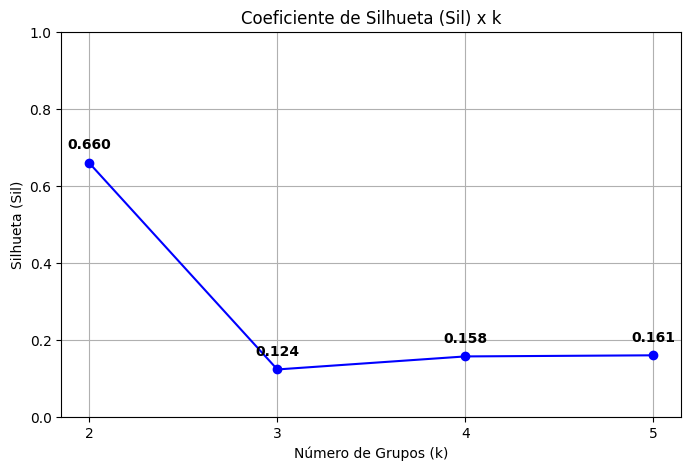

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_std, X_scaled_std, X = treinamento_k_means("StandardScaler")

In [ ]:
X_new_std.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,Nova_Classe
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,2
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,2
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,2
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,2
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,2


In [ ]:
X_new_std["Nova_Classe"].value_counts()

,count
Nova_Classe,
2,4567
1,34


# Normalizando com MinMaxScaler

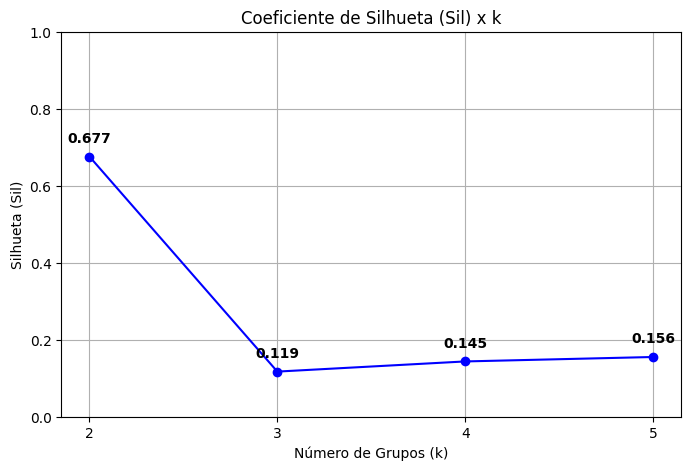

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_M, X_scaled_M, X  = treinamento_k_means("MinMaxScaler")

In [ ]:
X_new_M.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,Nova_Classe
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [ ]:
X_new_M["Nova_Classe"].value_counts()

,count
Nova_Classe,
1,4568
2,33


# Normalizando com RobustScaler

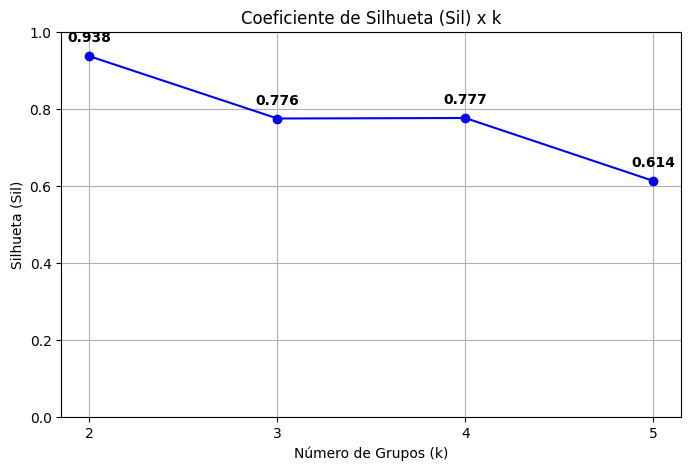

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_R, X_scaled_R, X  = treinamento_k_means("RobustScaler")

In [ ]:
X_new_R.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,Nova_Classe
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [ ]:
X_new_R["Nova_Classe"].value_counts()

,count
Nova_Classe,
1,4589
2,12


# Sem Normalização - Testando

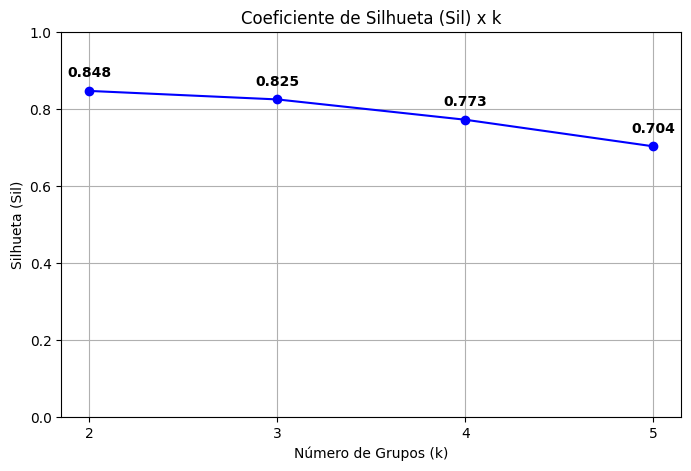

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_SN, X_scaled_SN, X  = treinamento_k_means("")

In [ ]:
X_new_SN.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,Nova_Classe
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,2
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [ ]:
X_new_SN["Nova_Classe"].value_counts()

,count
Nova_Classe,
1,4357
2,244


# Alterando Treinamento K-means para fazer PCA

In [ ]:
def treinamento_k_means_pca(normalization="StandardScaler"):
  # Separar a classe original (Última)
  X = data.iloc[:, :-1]
  y_original = data.iloc[:, -1]
  if normalization != "":
    if normalization == 'StandardScaler':
      scaler = StandardScaler()
    elif normalization == 'MinMaxScaler':
      scaler = MinMaxScaler()
    elif normalization == 'RobustScaler':
      scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)
  elif normalization == '':
    X_scaled = X.copy()

  pca_revan = PCA(n_components=0.95, random_state=42)
  X_pca = pca_revan.fit_transform(X_scaled)

  dimensoes_restantes = pca_revan.n_components_
  print(f"Redução de 57 para {dimensoes_restantes} dimensões.\n")

  k_values = [2, 3, 4, 5]
  silhouettes = []
  best_labels_per_k = {}

  for k in k_values:
      # executa o k-means 100 vezes (para cada k) e pega o resultado com a melhor (MENOR) função objetivo
      kmeans = KMeans(n_clusters=k, n_init=100, random_state=42)
      cluster_labels = kmeans.fit_predict(X_pca)

      sil_score = silhouette_score(X_pca, cluster_labels)
      silhouettes.append(sil_score)

      best_labels_per_k[k] = cluster_labels + 1

      distribuicao = Counter(cluster_labels + 1)
      print(f"Para k={k} (Sil: {sil_score:.3f}) | Distribuição: {dict(distribuicao)}")

  plt.figure(figsize=(8, 5))
  plt.plot(k_values, silhouettes, marker='o', linestyle='-', color='b')
  plt.title('Coeficiente de Silhueta (Sil) x k')
  plt.xlabel('Número de Grupos (k)')
  plt.ylabel('Silhueta (Sil)')
  plt.xticks(k_values)
  plt.ylim(0,1)
  for i, valor in enumerate(silhouettes):
      plt.annotate(f"{valor:.3f}",
                  (k_values[i], silhouettes[i]),
                  textcoords="offset points",
                  xytext=(0, 10),
                  ha='center',
                  fontsize=10,
                  fontweight='bold')

  plt.grid(True)
  plt.show()

  # Determinar k que maximiza a silhueta
  best_index = np.argmax(silhouettes)
  k_star = k_values[best_index]
  print(f"O número ideal de grupos (k*) é: {k_star}")

  # Criar o novo dataset com as verdadeiras classes
  X_new_pca = X.copy()
  X_new_pca['Nova_Classe'] = best_labels_per_k[k_star]
  return X_new_pca, X_scaled, X

# PCA

Redução de 57 para 48 dimensões.

Para k=2 (Sil: 0.666) | Distribuição: {np.int32(1): 4567, np.int32(2): 34}
Para k=3 (Sil: 0.136) | Distribuição: {np.int32(3): 3250, np.int32(1): 1321, np.int32(2): 30}
Para k=4 (Sil: 0.166) | Distribuição: {np.int32(3): 3070, np.int32(2): 1090, np.int32(1): 412, np.int32(4): 29}
Para k=5 (Sil: 0.101) | Distribuição: {np.int32(1): 2669, np.int32(2): 1295, np.int32(5): 208, np.int32(3): 400, np.int32(4): 29}


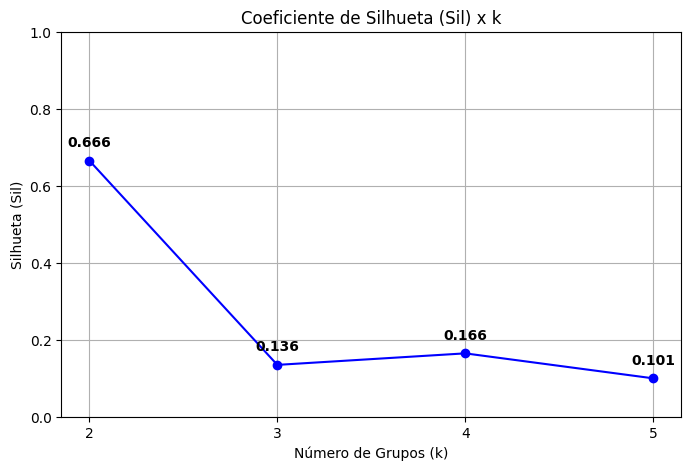

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_pca, X_scaled_pca, X  = treinamento_k_means_pca("StandardScaler")

In [ ]:
X_new_pca["Nova_Classe"].value_counts()

,count
Nova_Classe,
1,4567
2,34


Redução de 57 para 2 dimensões.

Para k=2 (Sil: 0.848) | Distribuição: {np.int32(1): 4357, np.int32(2): 244}
Para k=3 (Sil: 0.826) | Distribuição: {np.int32(1): 4251, np.int32(2): 345, np.int32(3): 5}
Para k=4 (Sil: 0.774) | Distribuição: {np.int32(1): 3978, np.int32(4): 526, np.int32(2): 92, np.int32(3): 5}
Para k=5 (Sil: 0.705) | Distribuição: {np.int32(2): 3560, np.int32(4): 268, np.int32(5): 81, np.int32(1): 687, np.int32(3): 5}


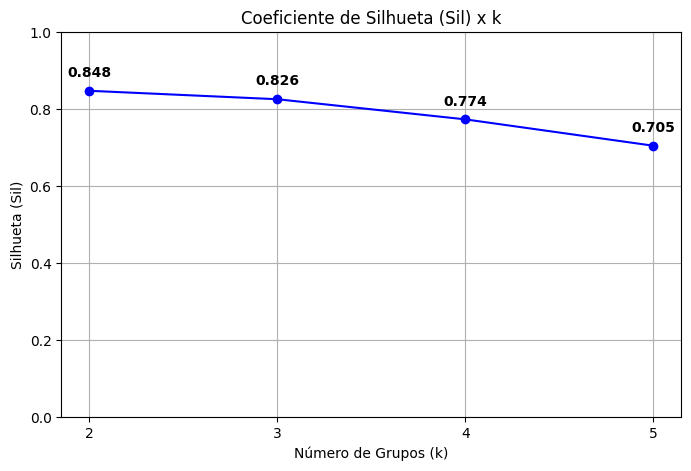

O número ideal de grupos (k*) é: 2


In [ ]:
X_new_pca_SN, X_scaled_pca_SN, X  = treinamento_k_means_pca("")

In [ ]:
X_new_pca_SN["Nova_Classe"].value_counts()

,count
Nova_Classe,
1,4357
2,244


# K-Vizinhos

Decidiu-se usar a partição originada por StandardScaler

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# 1. Separação inicial com dados crus
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, X_new_std['Nova_Classe'],
    test_size=0.20,
    stratify=X_new_std['Nova_Classe'],
    random_state=42
)

# 2. Fixação dos Hiperparâmetros via Validação Cruzada (Múltiplos Grids)
param_grid = [
    {
        'knn__n_neighbors': np.arange(1, 21),
        'knn__metric': ['minkowski'],
        'knn__p': [1, 2, 3, 4, 5]
    },
    {
        'knn__n_neighbors': np.arange(1, 21),
        'knn__metric': ['chebyshev']
    }
]

# --- TESTE 1: Sem Balanceamento ---
print("--- TESTE 1: SEM BALANCEAMENTO ---")
pipe_padrao = ImbPipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
grid_padrao = GridSearchCV(pipe_padrao, param_grid, cv=5, scoring='f1_macro')
grid_padrao.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_padrao.best_params_}")
# print(classification_report(y_test, grid_padrao.predict(X_test)))

print("F1 CV - Sem balanceamento:", grid_padrao.best_score_)

--- TESTE 1: SEM BALANCEAMENTO ---
Melhores parâmetros: {'knn__metric': 'minkowski', 'knn__n_neighbors': np.int64(1), 'knn__p': 2}
F1 CV - Sem balanceamento: 0.9908406446394127


In [ ]:
# --- TESTE 2: Random Oversampling ---
print("\n--- TESTE 2: RANDOM OVERSAMPLING ---")
pipe_ros = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('knn', KNeighborsClassifier())
])
grid_ros = GridSearchCV(pipe_ros, param_grid, cv=5, scoring='f1_macro')
grid_ros.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_ros.best_params_}")
# print(classification_report(y_test, grid_ros.predict(X_test)))
print("F1 CV - Random Oversampling:", grid_ros.best_score_)


--- TESTE 2: RANDOM OVERSAMPLING ---
Melhores parâmetros: {'knn__metric': 'minkowski', 'knn__n_neighbors': np.int64(1), 'knn__p': 2}
F1 CV - Random Oversampling: 0.9908406446394127


In [ ]:
# --- TESTE 3: SMOTE Oversampling ---
print("\n--- TESTE 3: SMOTE OVERSAMPLING ---")
pipe_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('knn', KNeighborsClassifier())
])
grid_smote = GridSearchCV(pipe_smote, param_grid, cv=5, scoring='f1_macro')
grid_smote.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_smote.best_params_}")
print("F1 CV - SMOTE:", grid_smote.best_score_)
# print(classification_report(y_tes,t grid_smote.predict(X_test)))


--- TESTE 3: SMOTE OVERSAMPLING ---
Melhores parâmetros: {'knn__metric': 'minkowski', 'knn__n_neighbors': np.int64(1), 'knn__p': 2}
F1 CV - SMOTE: 0.9908406446394127


In [ ]:
print(classification_report(y_test, grid_padrao.predict(X_test)))
print(classification_report(y_test, grid_ros.predict(X_test)))
print(classification_report(y_test, grid_smote.predict(X_test)))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00       229

    accuracy                           1.00       231
   macro avg       1.00      1.00      1.00       231
weighted avg       1.00      1.00      1.00       231

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00       229

    accuracy                           1.00       231
   macro avg       1.00      1.00      1.00       231
weighted avg       1.00      1.00      1.00       231

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00       229

    accuracy                           1.00       231
   macro avg       1.00      1.00      1.00       231
weighted avg       1.00      1.00      1.00       231



## K-Vizinhos Curva de Aprendizagem

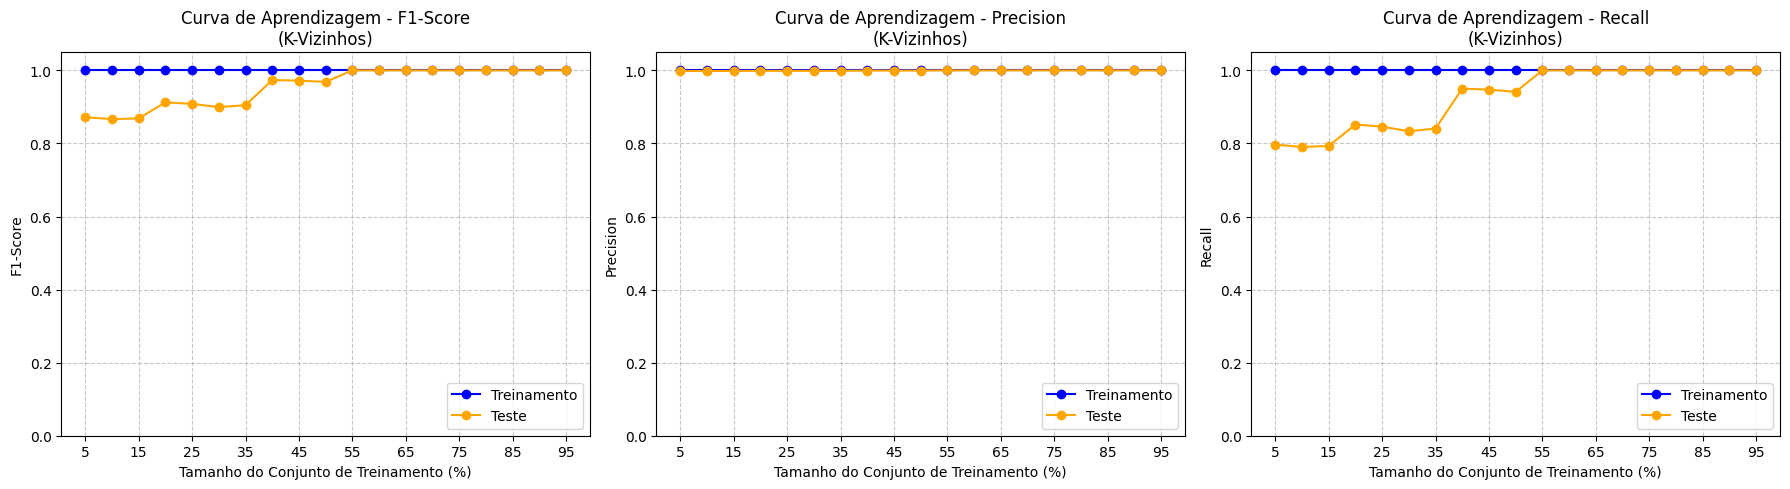

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Definindo as variáveis base (Assumindo os dados normalizados com StandardScaler)
y = X_new_std['Nova_Classe']
# y = X_new_SN['Nova_Classe']

# 2. Configurando o Pipeline com os melhores hiperparâmetros que você encontrou
best_knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=1, metric='minkowski', p=2))
])

# Proporções de 5% a 95% (0.05 a 0.95)
train_sizes = np.arange(0.05, 1.00, 0.05)

# Dicionários para armazenar as métricas em cada iteração
metrics = {
    'f1': {'train': [], 'test': []},
    'precision': {'train': [], 'test': []},
    'recall': {'train': [], 'test': []}
}

for size in train_sizes:
    # Divisão de (5%, 95%) a (95%, 5%) com amostragem estratificada
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        train_size=size,
        test_size=1.0 - size,
        stratify=y,
        random_state=42
    )

    # Treinando o modelo para a fatia atual
    best_knn_pipeline.fit(X_train, y_train)

    # Gerando predições para treinamento e teste
    y_train_pred = best_knn_pipeline.predict(X_train)
    y_test_pred = best_knn_pipeline.predict(X_test)

    # Calculando as métricas (average='macro' pois é um problema multiclasse)
    metrics['f1']['train'].append(f1_score(y_train, y_train_pred, average='macro'))
    metrics['f1']['test'].append(f1_score(y_test, y_test_pred, average='macro'))

    metrics['precision']['train'].append(precision_score(y_train, y_train_pred, average='macro', zero_division=0))
    metrics['precision']['test'].append(precision_score(y_test, y_test_pred, average='macro', zero_division=0))

    metrics['recall']['train'].append(recall_score(y_train, y_train_pred, average='macro'))
    metrics['recall']['test'].append(recall_score(y_test, y_test_pred, average='macro'))

# 3. Plotagem das Curvas de Aprendizagem para cada Métrica
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titulos = ['F1-Score', 'Precision', 'Recall']
chaves = ['f1', 'precision', 'recall']

for ax, titulo, chave in zip(axes, titulos, chaves):
    # Eixo X em porcentagem (multiplicando train_sizes por 100)
    ax.plot(train_sizes * 100, metrics[chave]['train'], label='Treinamento', marker='o', color='blue')
    ax.plot(train_sizes * 100, metrics[chave]['test'], label='Teste', marker='o', color='orange')

    ax.set_title(f'Curva de Aprendizagem - {titulo}\n(K-Vizinhos)')
    ax.set_xlabel('Tamanho do Conjunto de Treinamento (%)')
    ax.set_ylabel(titulo)
    ax.set_xticks(np.arange(5, 100, 10))
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right')
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Testando Visualização Para Melhor Entendimento da Curva de Aprendizagem

In [ ]:
def treino_percentagem(size=0.3):
  from sklearn.metrics import precision_recall_fscore_support
  from sklearn.model_selection import train_test_split

  # Vamos pegar apenas um tamanho de treino de exemplo (ex: 30%)
  # size = 0.30

  X_train, X_test, y_train, y_test = train_test_split(
      X, y,
      train_size=size,
      test_size=1.0 - size,
      stratify=y,
      random_state=42
  )

  # Treinando o modelo para a fatia atual
  best_knn_pipeline.fit(X_train, y_train)

  # Gerando predições para teste
  y_test_pred = best_knn_pipeline.predict(X_test)

  # Calculando métricas separadas por classe (average=None)
  # Isso retorna arrays com os valores para a Classe 1 e Classe 2 separadamente
  precision, recall, f1, support = precision_recall_fscore_support(
      y_test, y_test_pred, average=None, zero_division=0
  )

  classes = best_knn_pipeline.classes_

  print(f"--- Avaliação com {size*100}% de dados de treino ---")
  for i, cls in enumerate(classes):
      print(f"\nClasse {cls}:")
      print(f"  Contagem exata (Support): {support[i]}")
      print(f"  Precision: {precision[i]:.4f}")
      print(f"  Recall: {recall[i]:.4f}")
      print(f"  F1-Score: {f1[i]:.4f}")


In [ ]:
treino_percentagem(0.3)

--- Avaliação com 30.0% de dados de treino ---

Classe 1:
  Contagem exata (Support): 24
  Precision: 1.0000
  Recall: 0.6667
  F1-Score: 0.8000

Classe 2:
  Contagem exata (Support): 3197
  Precision: 0.9975
  Recall: 1.0000
  F1-Score: 0.9988


In [ ]:
treino_percentagem(0.45)

--- Avaliação com 45.0% de dados de treino ---

Classe 1:
  Contagem exata (Support): 19
  Precision: 1.0000
  Recall: 0.8947
  F1-Score: 0.9444

Classe 2:
  Contagem exata (Support): 2512
  Precision: 0.9992
  Recall: 1.0000
  F1-Score: 0.9996


In [ ]:
treino_percentagem(0.5)

--- Avaliação com 50.0% de dados de treino ---

Classe 1:
  Contagem exata (Support): 17
  Precision: 1.0000
  Recall: 0.8824
  F1-Score: 0.9375

Classe 2:
  Contagem exata (Support): 2284
  Precision: 0.9991
  Recall: 1.0000
  F1-Score: 0.9996


In [ ]:
treino_percentagem(0.55)

--- Avaliação com 55.00000000000001% de dados de treino ---

Classe 1:
  Contagem exata (Support): 15
  Precision: 1.0000
  Recall: 1.0000
  F1-Score: 1.0000

Classe 2:
  Contagem exata (Support): 2056
  Precision: 1.0000
  Recall: 1.0000
  F1-Score: 1.0000


# Testando o Impacto do Agrupamento Gerado pelo caso de Sem Normalização Na Curva de Aprendizagem

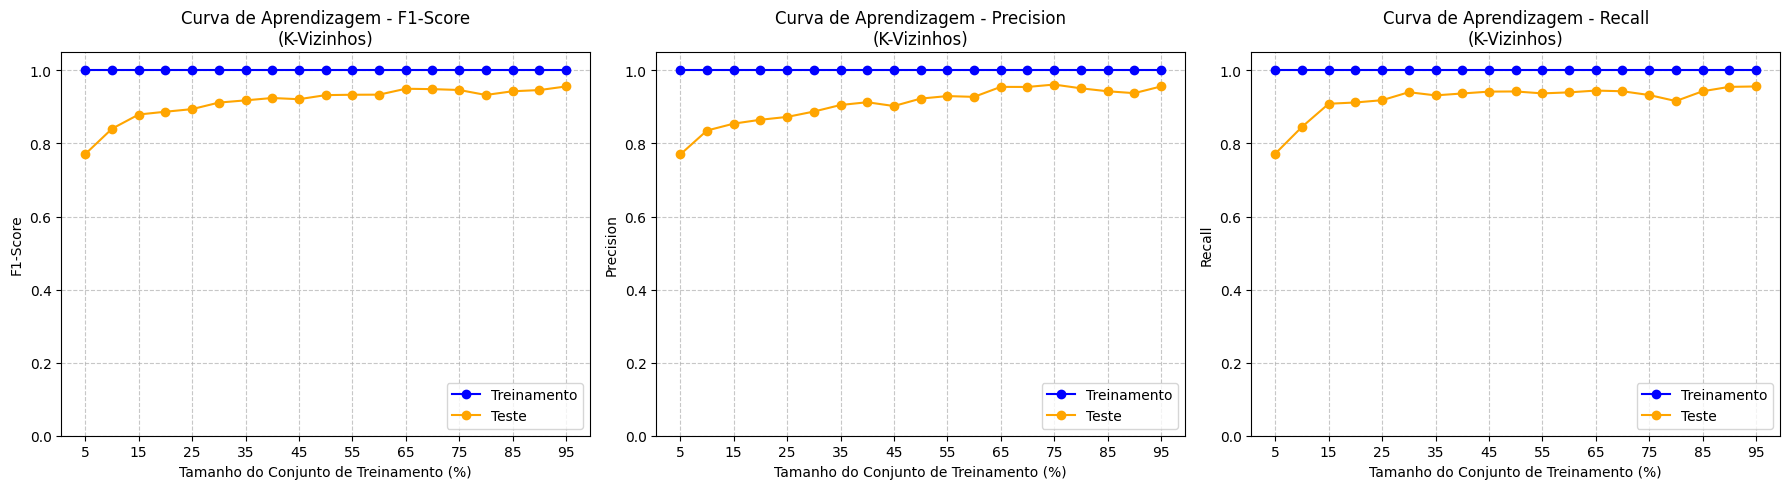

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Definindo as variáveis base (Assumindo os dados normalizados com StandardScaler)
# y = X_new_std['Nova_Classe']
y = X_new_SN['Nova_Classe']

# 2. Configurando o Pipeline com os melhores hiperparâmetros que você encontrou
best_knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=1, metric='minkowski', p=2))
])

# Proporções de 5% a 95% (0.05 a 0.95)
train_sizes = np.arange(0.05, 1.00, 0.05)

# Dicionários para armazenar as métricas em cada iteração
metrics = {
    'f1': {'train': [], 'test': []},
    'precision': {'train': [], 'test': []},
    'recall': {'train': [], 'test': []}
}

for size in train_sizes:
    # Divisão de (5%, 95%) a (95%, 5%) com amostragem estratificada
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        train_size=size,
        test_size=1.0 - size,
        stratify=y,
        random_state=42
    )

    # Treinando o modelo para a fatia atual
    best_knn_pipeline.fit(X_train, y_train)

    # Gerando predições para treinamento e teste
    y_train_pred = best_knn_pipeline.predict(X_train)
    y_test_pred = best_knn_pipeline.predict(X_test)

    # Calculando as métricas (average='macro' pois é um problema multiclasse)
    metrics['f1']['train'].append(f1_score(y_train, y_train_pred, average='macro'))
    metrics['f1']['test'].append(f1_score(y_test, y_test_pred, average='macro'))

    metrics['precision']['train'].append(precision_score(y_train, y_train_pred, average='macro', zero_division=0))
    metrics['precision']['test'].append(precision_score(y_test, y_test_pred, average='macro', zero_division=0))

    metrics['recall']['train'].append(recall_score(y_train, y_train_pred, average='macro'))
    metrics['recall']['test'].append(recall_score(y_test, y_test_pred, average='macro'))

# 3. Plotagem das Curvas de Aprendizagem para cada Métrica
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titulos = ['F1-Score', 'Precision', 'Recall']
chaves = ['f1', 'precision', 'recall']

for ax, titulo, chave in zip(axes, titulos, chaves):
    # Eixo X em porcentagem (multiplicando train_sizes por 100)
    ax.plot(train_sizes * 100, metrics[chave]['train'], label='Treinamento', marker='o', color='blue')
    ax.plot(train_sizes * 100, metrics[chave]['test'], label='Teste', marker='o', color='orange')

    ax.set_title(f'Curva de Aprendizagem - {titulo}\n(K-Vizinhos)')
    ax.set_xlabel('Tamanho do Conjunto de Treinamento (%)')
    ax.set_ylabel(titulo)
    ax.set_xticks(np.arange(5, 100, 10))
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right')
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()




# Regressão Logística

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Define X from X_new_std by dropping the target column
X = X_new_std.drop(columns=['Nova_Classe'])

# 1. Separação inicial com dados crus
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, X_new_std['Nova_Classe'],
    test_size=0.20,
    stratify=X_new_std['Nova_Classe'],
    random_state=42
)

# 2. Grid de hiperparâmetros
param_grid_lr = [
    {
        'lr__penalty': ['l2'],
        'lr__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'lr__solver': ['lbfgs'],
        'lr__max_iter': [5000]
    },
    {
        'lr__penalty': ['l1'],
        'lr__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'lr__solver': ['liblinear'],
        'lr__max_iter': [5000]
    }
]

# --- TESTE 1: Sem Balanceamento ---
print("--- TESTE 1: SEM BALANCEAMENTO ---")
pipe_lr_padrao = ImbPipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42))
])
grid_lr_padrao = GridSearchCV(pipe_lr_padrao, param_grid_lr, cv=5, scoring='f1_macro')
grid_lr_padrao.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_lr_padrao.best_params_}")
print("F1 CV - Sem balanceamento:", grid_lr_padrao.best_score_)

# --- TESTE 2: Random Oversampling ---
print("\n--- TESTE 2: RANDOM OVERSAMPLING ---")
pipe_lr_ros = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('lr', LogisticRegression(random_state=42))
])
grid_lr_ros = GridSearchCV(pipe_lr_ros, param_grid_lr, cv=5, scoring='f1_macro')
grid_lr_ros.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_lr_ros.best_params_}")
print("F1 CV - Random Oversampling:", grid_lr_ros.best_score_)

# --- TESTE 3: SMOTE Oversampling ---
print("\n--- TESTE 3: SMOTE OVERSAMPLING ---")
pipe_lr_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('lr', LogisticRegression(random_state=42))
])
grid_lr_smote = GridSearchCV(pipe_lr_smote, param_grid_lr, cv=5, scoring='f1_macro')
grid_lr_smote.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_lr_smote.best_params_}")
print("F1 CV - SMOTE:", grid_lr_smote.best_score_)

# Avaliação no conjunto de teste
print(classification_report(y_test, grid_lr_padrao.predict(X_test)))
print(classification_report(y_test, grid_lr_ros.predict(X_test)))
print(classification_report(y_test, grid_lr_smote.predict(X_test)))

--- TESTE 1: SEM BALANCEAMENTO ---
Melhores parâmetros: {'lr__C': 0.1, 'lr__max_iter': 5000, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}
F1 CV - Sem balanceamento: 1.0

--- TESTE 2: RANDOM OVERSAMPLING ---
Melhores parâmetros: {'lr__C': 1, 'lr__max_iter': 5000, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}
F1 CV - Random Oversampling: 0.9753189490628851

--- TESTE 3: SMOTE OVERSAMPLING ---
Melhores parâmetros: {'lr__C': 1, 'lr__max_iter': 5000, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}
F1 CV - SMOTE: 0.97641775614245
              precision    recall  f1-score   support

           1       0.88      1.00      0.93         7
           2       1.00      1.00      1.00       914

    accuracy                           1.00       921
   macro avg       0.94      1.00      0.97       921
weighted avg       1.00      1.00      1.00       921

              precision    recall  f1-score   support

           1       0.88      1.00      0.93         7
           2       1.00      1.00      1.

## Regressão Logística - Curva de Aprendizagem

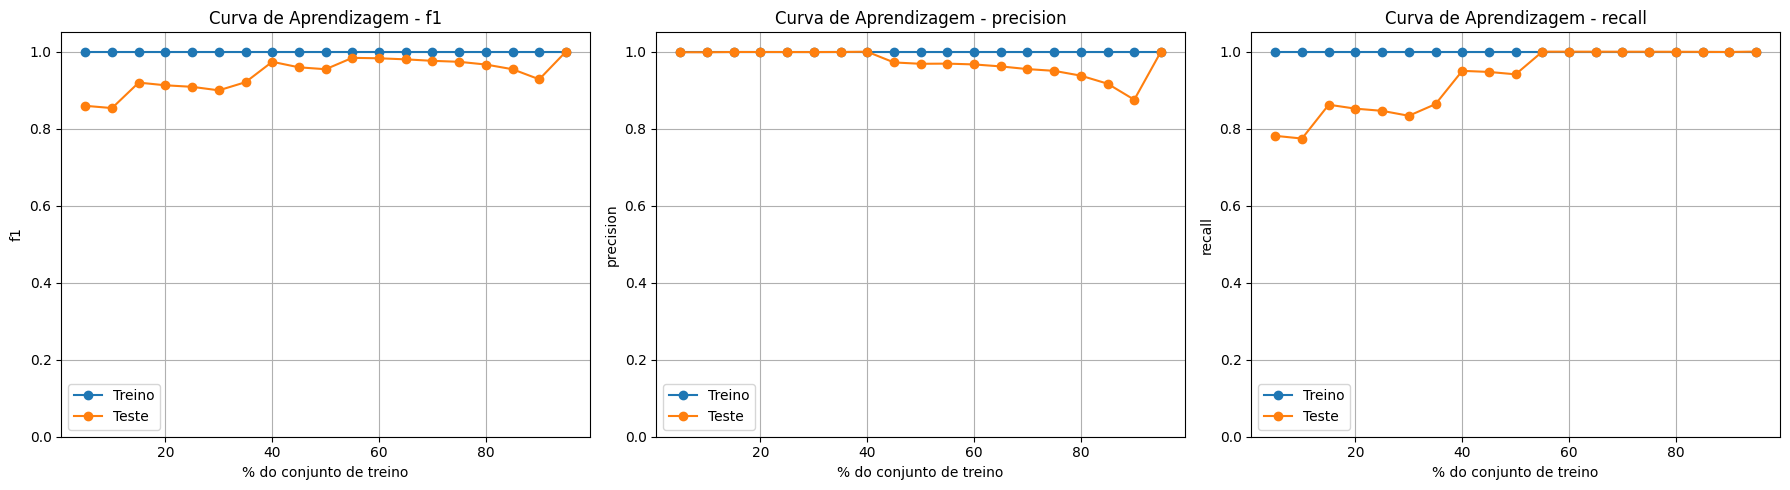

In [ ]:
# Regressão Logística - Curva de Aprendizagem
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Usa X e y já definidos no bloco anterior (não depende de X_new_std diretamente)
# Caso essa célula seja executada isoladamente, garanta X e y assim:
# X_new_std, X_scaled_std, X = treinamento_k_means("StandardScaler")
# y = X_new_std['Nova_Classe']

# Melhores hiperparâmetros encontrados no GridSearchCV (sem balanceamento, que teve o melhor F1 CV)
best_lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(
        C=grid_lr_padrao.best_params_['lr__C'],
        penalty=grid_lr_padrao.best_params_['lr__penalty'],
        solver=grid_lr_padrao.best_params_['lr__solver'],
        max_iter=5000,
        random_state=42
    ))
])

train_sizes = np.arange(0.05, 1.00, 0.05)

metrics_lr = {
    'f1': {'train': [], 'test': []},
    'precision': {'train': [], 'test': []},
    'recall': {'train': [], 'test': []}
}

for size in train_sizes:
    X_train, X_test_lc, y_train, y_test_lc = train_test_split(
        X, y,
        train_size=size,
        test_size=1.0 - size,
        stratify=y,
        random_state=42
    )

    best_lr_pipeline.fit(X_train, y_train)

    y_train_pred = best_lr_pipeline.predict(X_train)
    y_test_pred = best_lr_pipeline.predict(X_test_lc)

    metrics_lr['f1']['train'].append(f1_score(y_train, y_train_pred, average='macro'))
    metrics_lr['f1']['test'].append(f1_score(y_test_lc, y_test_pred, average='macro'))
    metrics_lr['precision']['train'].append(precision_score(y_train, y_train_pred, average='macro', zero_division=0))
    metrics_lr['precision']['test'].append(precision_score(y_test_lc, y_test_pred, average='macro', zero_division=0))
    metrics_lr['recall']['train'].append(recall_score(y_train, y_train_pred, average='macro'))
    metrics_lr['recall']['test'].append(recall_score(y_test_lc, y_test_pred, average='macro'))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (metric_name, values) in zip(axes, metrics_lr.items()):
    ax.plot(train_sizes * 100, values['train'], marker='o', label='Treino')
    ax.plot(train_sizes * 100, values['test'], marker='o', label='Teste')
    ax.set_title(f'Curva de Aprendizagem - {metric_name}')
    ax.set_xlabel('% do conjunto de treino')
    ax.set_ylabel(metric_name)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

# Bayesiano Ingênuo

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Define X e y
X = X_new_std.drop(columns=['Nova_Classe'])
y = X_new_std['Nova_Classe']

# 1. Separação inicial
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2. Grid de hiperparâmetros
param_grid_nb = {
    'nb__var_smoothing': np.logspace(-12, -1, 12)
}


# --- TESTE 1: Sem Balanceamento ---
print("--- TESTE 1: SEM BALANCEAMENTO ---")

pipe_nb_padrao = ImbPipeline([
    ('nb', GaussianNB())
])

grid_nb_padrao = GridSearchCV(
    pipe_nb_padrao,
    param_grid_nb,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1S
)

grid_nb_padrao.fit(X_train_val, y_train_val)

print(f"Melhores parâmetros: {grid_nb_padrao.best_params_}")
print("F1 CV - Sem balanceamento:", grid_nb_padrao.best_score_)


# --- TESTE 2: Random Oversampling ---
print("\n--- TESTE 2: RANDOM OVERSAMPLING ---")

pipe_nb_ros = ImbPipeline([
    ('ros', RandomOverSampler(random_state=42)),
    ('nb', GaussianNB())
])

grid_nb_ros = GridSearchCV(
    pipe_nb_ros,
    param_grid_nb,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_nb_ros.fit(X_train_val, y_train_val)

print(f"Melhores parâmetros: {grid_nb_ros.best_params_}")
print("F1 CV - Random Oversampling:", grid_nb_ros.best_score_)


# --- TESTE 3: SMOTE ---
print("\n--- TESTE 3: SMOTE OVERSAMPLING ---")

pipe_nb_smote = ImbPipeline([
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('nb', GaussianNB())
])

grid_nb_smote = GridSearchCV(
    pipe_nb_smote,
    param_grid_nb,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_nb_smote.fit(X_train_val, y_train_val)

print(f"Melhores parâmetros: {grid_nb_smote.best_params_}")
print("F1 CV - SMOTE:", grid_nb_smote.best_score_)


# 3. Avaliação no conjunto de teste
print("\n--- AVALIAÇÃO NO CONJUNTO DE TESTE ---")

print("\nNaive Bayes - Sem balanceamento:")
print(classification_report(
    y_test,
    grid_nb_padrao.predict(X_test)
))

print("\nNaive Bayes - Random Oversampling:")
print(classification_report(
    y_test,
    grid_nb_ros.predict(X_test)
))

print("\nNaive Bayes - SMOTE:")
print(classification_report(
    y_test,
    grid_nb_smote.predict(X_test)
))

--- TESTE 1: SEM BALANCEAMENTO ---
Melhores parâmetros: {'nb__var_smoothing': np.float64(1e-06)}
F1 CV - Sem balanceamento: 0.7899907025880466

--- TESTE 2: RANDOM OVERSAMPLING ---
Melhores parâmetros: {'nb__var_smoothing': np.float64(1e-07)}
F1 CV - Random Oversampling: 0.7487891436951007

--- TESTE 3: SMOTE OVERSAMPLING ---
Melhores parâmetros: {'nb__var_smoothing': np.float64(1e-07)}
F1 CV - SMOTE: 0.8095511674449316

--- AVALIAÇÃO NO CONJUNTO DE TESTE ---

Naive Bayes - Sem balanceamento:
              precision    recall  f1-score   support

           1       0.47      1.00      0.64         7
           2       1.00      0.99      1.00       914

    accuracy                           0.99       921
   macro avg       0.73      1.00      0.82       921
weighted avg       1.00      0.99      0.99       921


Naive Bayes - Random Oversampling:
              precision    recall  f1-score   support

           1       0.33      1.00      0.50         7
           2       1.00      0

## Bayesiano Ingênuo - Curva de Aprendizagem

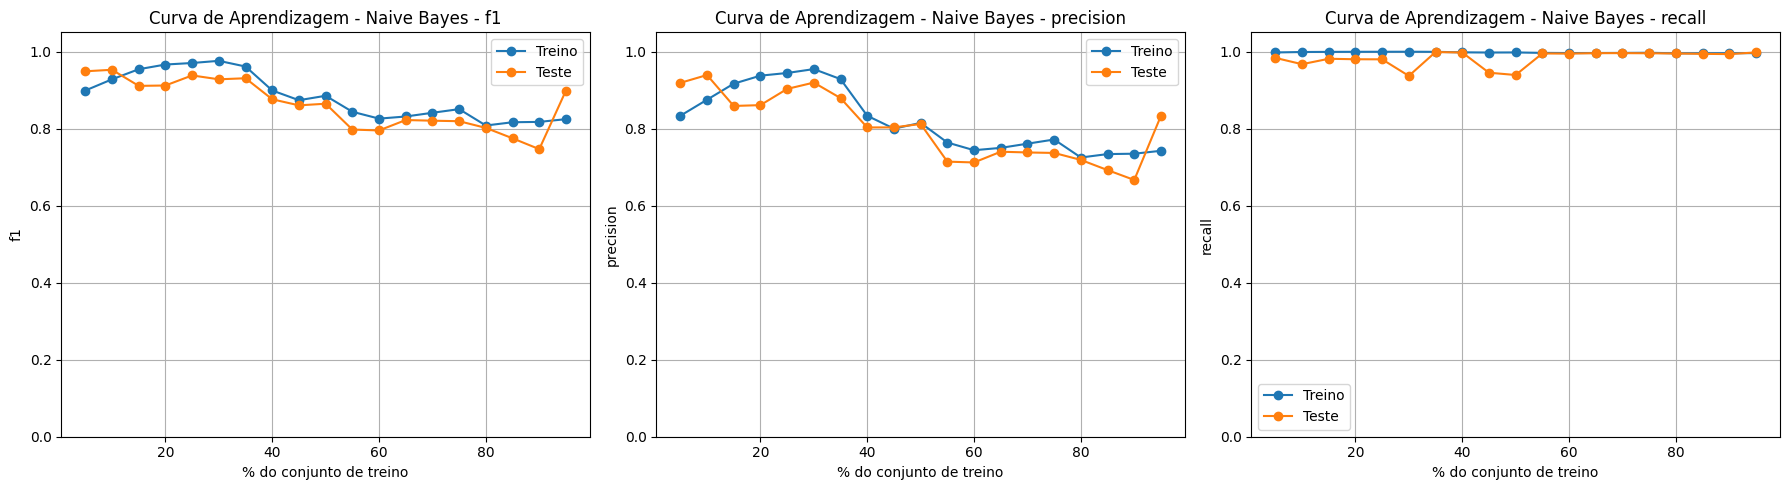

In [ ]:
# Naive Bayes - Curva de Aprendizagem

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import precision_score, recall_score, f1_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Usa X e y já definidos anteriormente
# X = X_new_std.drop(columns=['Nova_Classe'])
# y = X_new_std['Nova_Classe']

train_sizes = np.arange(0.05, 1.00, 0.05)

metrics_nb = {
    'f1': {'train': [], 'test': []},
    'precision': {'train': [], 'test': []},
    'recall': {'train': [], 'test': []}
}

# Melhor var_smoothing encontrado pelo GridSearchCV
best_var_smoothing = grid_nb_smote.best_params_['nb__var_smoothing']

for size in train_sizes:

    X_train, X_test_lc, y_train, y_test_lc = train_test_split(
        X,
        y,
        train_size=size,
        test_size=1.0 - size,
        stratify=y,
        random_state=42
    )

    # Quantidade de exemplos da classe minoritária
    menor_classe = y_train.value_counts().min()

    # O SMOTE precisa de k_neighbors + 1 exemplos
    # Usamos no máximo 5 vizinhos, mas reduzimos quando necessário
    k_smote = min(5, menor_classe - 1)

    # Caso não haja exemplos suficientes para aplicar SMOTE
    if k_smote >= 1:

        best_nb_pipeline = ImbPipeline([
            ('smote', SMOTE(
                random_state=42,
                k_neighbors=k_smote
            )),
            ('nb', GaussianNB(
                var_smoothing=best_var_smoothing
            ))
        ])

    else:

        # Se houver apenas um exemplo da classe minoritária,
        # não é possível aplicar SMOTE
        best_nb_pipeline = GaussianNB(
            var_smoothing=best_var_smoothing
        )

    # Treinamento
    best_nb_pipeline.fit(X_train, y_train)

    # Predições
    y_train_pred = best_nb_pipeline.predict(X_train)
    y_test_pred = best_nb_pipeline.predict(X_test_lc)

    # F1
    metrics_nb['f1']['train'].append(
        f1_score(
            y_train,
            y_train_pred,
            average='macro',
            zero_division=0
        )
    )

    metrics_nb['f1']['test'].append(
        f1_score(
            y_test_lc,
            y_test_pred,
            average='macro',
            zero_division=0
        )
    )

    # Precision
    metrics_nb['precision']['train'].append(
        precision_score(
            y_train,
            y_train_pred,
            average='macro',
            zero_division=0
        )
    )

    metrics_nb['precision']['test'].append(
        precision_score(
            y_test_lc,
            y_test_pred,
            average='macro',
            zero_division=0
        )
    )

    # Recall
    metrics_nb['recall']['train'].append(
        recall_score(
            y_train,
            y_train_pred,
            average='macro',
            zero_division=0
        )
    )

    metrics_nb['recall']['test'].append(
        recall_score(
            y_test_lc,
            y_test_pred,
            average='macro',
            zero_division=0
        )
    )


# Gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (metric_name, values) in zip(axes, metrics_nb.items()):

    ax.plot(
        train_sizes * 100,
        values['train'],
        marker='o',
        label='Treino'
    )

    ax.plot(
        train_sizes * 100,
        values['test'],
        marker='o',
        label='Teste'
    )

    ax.set_title(
        f'Curva de Aprendizagem - Naive Bayes - {metric_name}'
    )
    ax.set_xlabel('% do conjunto de treino')
    ax.set_ylabel(metric_name)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Árvore de Decisão

In [ ]:
# Importações necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# 1. Define X e y conforme a partição gerada pelo K-means
X = X_new_std.drop(columns=['Nova_Classe'])
y = X_new_std['Nova_Classe']

# Separação do dataset (80% treino/validação, 20% teste) com amostragem estratificada
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2. Definindo a grade de hiperparâmetros para Árvore de Decisão
param_grid_dt = {
    'dt__criterion': ['gini', 'entropy'],
    'dt__max_depth': [None, 5, 10, 15, 20],
    'dt__min_samples_split': [2, 5, 10]
}

# --- TESTE 1: Sem Balanceamento ---
print("--- ÁRVORE DE DECISÃO: SEM BALANCEAMENTO ---")
pipe_dt_padrao = ImbPipeline([
    ('scaler', StandardScaler()),
    ('dt', DecisionTreeClassifier(random_state=42))
])
grid_dt_padrao = GridSearchCV(pipe_dt_padrao, param_grid_dt, cv=5, scoring='f1_macro')
grid_dt_padrao.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_dt_padrao.best_params_}")
print(f"F1 CV - Sem balanceamento: {grid_dt_padrao.best_score_:.4f}")

# --- TESTE 2: Random Oversampling ---
print("\n--- ÁRVORE DE DECISÃO: RANDOM OVERSAMPLING ---")
pipe_dt_ros = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42))
])
grid_dt_ros = GridSearchCV(pipe_dt_ros, param_grid_dt, cv=5, scoring='f1_macro')
grid_dt_ros.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_dt_ros.best_params_}")
print(f"F1 CV - ROS: {grid_dt_ros.best_score_:.4f}")

# --- TESTE 3: SMOTE ---
print("\n--- ÁRVORE DE DECISÃO: SMOTE OVERSAMPLING ---")
pipe_dt_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('dt', DecisionTreeClassifier(random_state=42))
])
grid_dt_smote = GridSearchCV(pipe_dt_smote, param_grid_dt, cv=5, scoring='f1_macro')
grid_dt_smote.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_dt_smote.best_params_}")
print(f"F1 CV - SMOTE: {grid_dt_smote.best_score_:.4f}")

# 3. Avaliação no conjunto de Teste (20% isolados)
print("\nRelatório de Classificação (Melhor Modelo DT no Teste):")
# Extrai o melhor modelo (assumindo o grid_dt_padrao, mas você pode alterar para grid_dt_smote se for melhor)
best_dt_model = grid_dt_padrao.best_estimator_
y_pred_dt = best_dt_model.predict(X_test)
print(classification_report(y_test, y_pred_dt, digits = 4))

--- ÁRVORE DE DECISÃO: SEM BALANCEAMENTO ---
Melhores parâmetros: {'dt__criterion': 'gini', 'dt__max_depth': None, 'dt__min_samples_split': 2}
F1 CV - Sem balanceamento: 0.9753

--- ÁRVORE DE DECISÃO: RANDOM OVERSAMPLING ---
Melhores parâmetros: {'dt__criterion': 'gini', 'dt__max_depth': None, 'dt__min_samples_split': 2}
F1 CV - ROS: 0.9627

--- ÁRVORE DE DECISÃO: SMOTE OVERSAMPLING ---
Melhores parâmetros: {'dt__criterion': 'gini', 'dt__max_depth': None, 'dt__min_samples_split': 2}
F1 CV - SMOTE: 0.9719

Relatório de Classificação (Melhor Modelo DT no Teste):
              precision    recall  f1-score   support

           1     0.8750    1.0000    0.9333         7
           2     1.0000    0.9989    0.9995       914

    accuracy                         0.9989       921
   macro avg     0.9375    0.9995    0.9664       921
weighted avg     0.9990    0.9989    0.9990       921



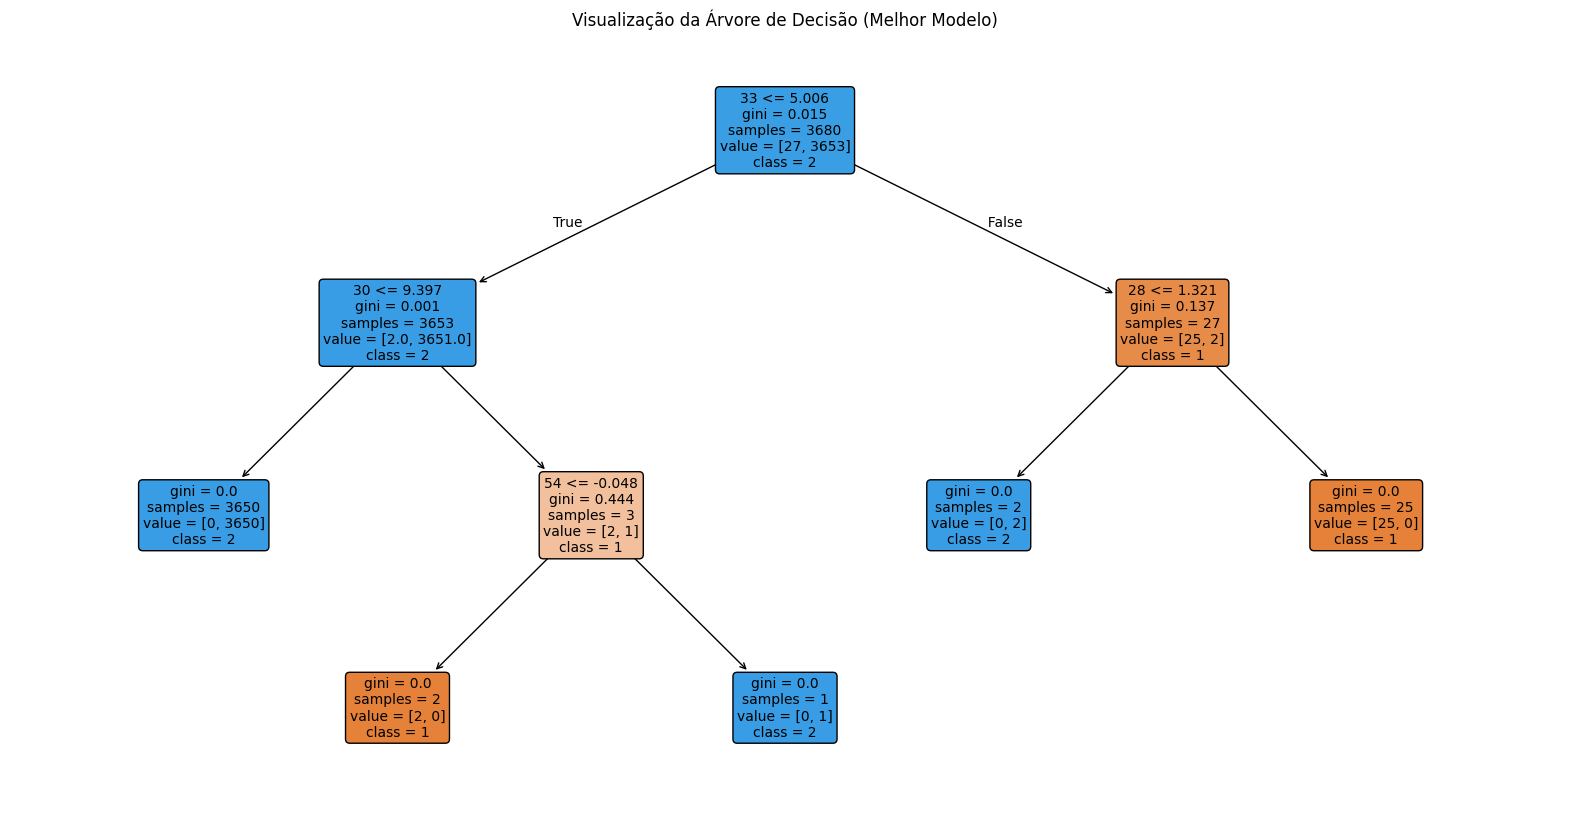


--- Regras da Árvore de Decisão ---
|--- 33 <= 5.01
|   |--- 30 <= 9.40
|   |   |--- class: 2
|   |--- 30 >  9.40
|   |   |--- 54 <= -0.05
|   |   |   |--- class: 1
|   |   |--- 54 >  -0.05
|   |   |   |--- class: 2
|--- 33 >  5.01
|   |--- 28 <= 1.32
|   |   |--- class: 2
|   |--- 28 >  1.32
|   |   |--- class: 1



In [ ]:
from sklearn.tree import plot_tree, export_text
import matplotlib.pyplot as plt

# 1. Extrai apenas o modelo de árvore de decisão de dentro do melhor pipeline
modelo_arvore = best_dt_model.named_steps['dt']

# 2. Gera a visualização gráfica da árvore
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_arvore,
    feature_names=X.columns,
    class_names=[str(c) for c in best_dt_model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visualização da Árvore de Decisão (Melhor Modelo)")
plt.show()

# 3. Imprime as regras da árvore em formato de texto (opcional)
print("\n--- Regras da Árvore de Decisão ---")
regras_arvore = export_text(modelo_arvore, feature_names=list(X.columns))
print(regras_arvore)

## Árvore de Decisão : Curvas de Aprendizado

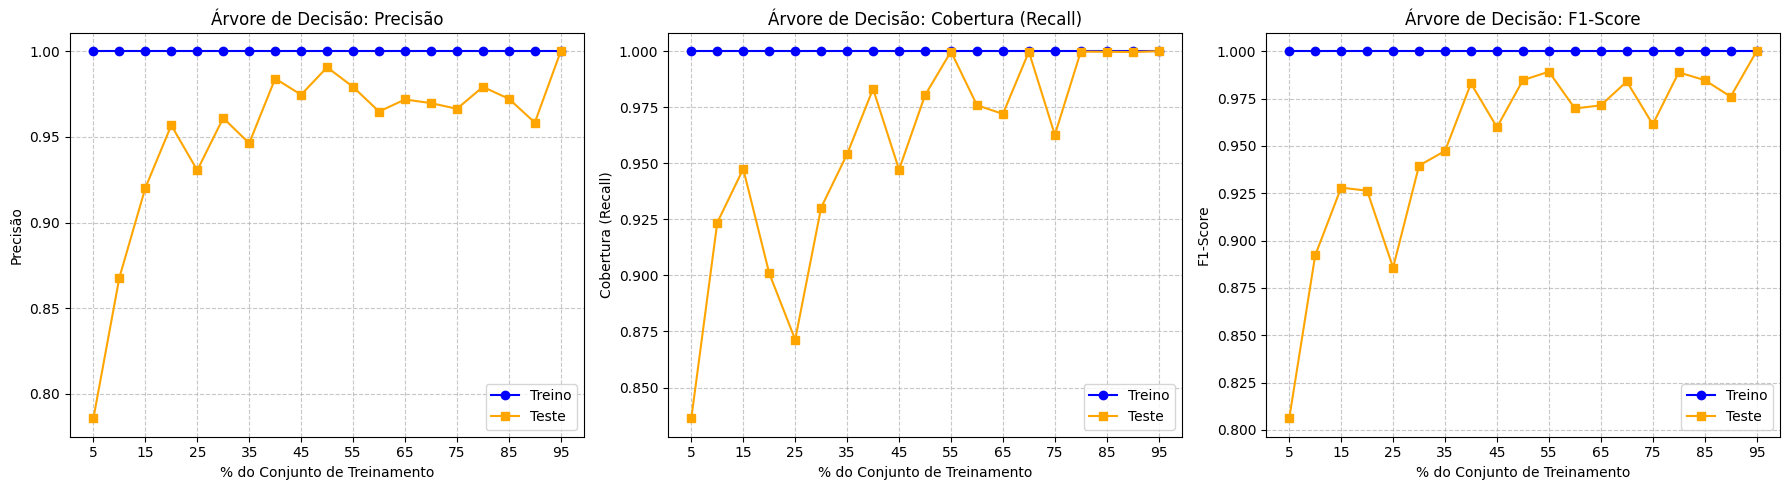

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import precision_score, recall_score, f1_score

# Proporções de treino de 5% a 95% (0.05 a 0.95) conforme especificação do projeto
train_proportions = np.round(np.arange(0.05, 0.96, 0.05), 2)

# Dicionários para armazenar as médias das métricas
metrics_train = {'precision': [], 'recall': [], 'f1': []}
metrics_test = {'precision': [], 'recall': [], 'f1': []}

# Utilizando o melhor modelo da Árvore de Decisão encontrado no GridSearchCV
# (Se o SMOTE teve um resultado melhor nas suas análises, troque para grid_dt_smote.best_estimator_)
best_dt_model = grid_dt_padrao.best_estimator_

# Variável alvo já instanciada anteriormente
y_full = y

for train_size in train_proportions:
    # Amostragem estratificada com 3 repetições (splits) para garantir estabilidade na média
    sss = StratifiedShuffleSplit(n_splits=3, train_size=train_size, test_size=1.0-train_size, random_state=42)

    tr_prec, tr_rec, tr_f1 = [], [], []
    te_prec, te_rec, te_f1 = [], [], []

    for train_idx, test_idx in sss.split(X, y_full):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y_full.iloc[train_idx], y_full.iloc[test_idx]

        # Treina o modelo com a proporção atual
        best_dt_model.fit(X_tr, y_tr)

        # Previsões para treino e teste
        y_tr_pred = best_dt_model.predict(X_tr)
        y_te_pred = best_dt_model.predict(X_te)

        # Calculando métricas usando 'macro' devido ao forte desbalanceamento das classes
        tr_prec.append(precision_score(y_tr, y_tr_pred, average='macro', zero_division=0))
        tr_rec.append(recall_score(y_tr, y_tr_pred, average='macro', zero_division=0))
        tr_f1.append(f1_score(y_tr, y_tr_pred, average='macro', zero_division=0))

        te_prec.append(precision_score(y_te, y_te_pred, average='macro', zero_division=0))
        te_rec.append(recall_score(y_te, y_te_pred, average='macro', zero_division=0))
        te_f1.append(f1_score(y_te, y_te_pred, average='macro', zero_division=0))

    # Armazena a média dos splits para a proporção atual
    metrics_train['precision'].append(np.mean(tr_prec))
    metrics_train['recall'].append(np.mean(tr_rec))
    metrics_train['f1'].append(np.mean(tr_f1))

    metrics_test['precision'].append(np.mean(te_prec))
    metrics_test['recall'].append(np.mean(te_rec))
    metrics_test['f1'].append(np.mean(te_f1))

# Plotagem das métricas exigidas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metric_names = [('precision', 'Precisão'), ('recall', 'Cobertura (Recall)'), ('f1', 'F1-Score')]

for ax, (key, title) in zip(axes, metric_names):
    ax.plot(train_proportions * 100, metrics_train[key], label='Treino', marker='o', color='blue')
    ax.plot(train_proportions * 100, metrics_test[key], label='Teste', marker='s', color='orange')
    ax.set_title(f'Árvore de Decisão: {title}')
    ax.set_xlabel('% do Conjunto de Treinamento')
    ax.set_ylabel(title)
    ax.set_xticks(np.arange(5, 100, 10))
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend()

plt.tight_layout()
plt.show()

# Random Forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1. Definição da grelha de hiperparâmetros para o Random Forest
param_grid_rf = {
    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_split': [2, 5]
}

# --- TESTE 1: Sem Balanceamento ---
print("--- RANDOM FOREST: SEM BALANCEAMENTO ---")
pipe_rf_padrao = ImbPipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(random_state=42))
])
grid_rf_padrao = GridSearchCV(pipe_rf_padrao, param_grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
grid_rf_padrao.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_rf_padrao.best_params_}")
print(f"F1 CV - Sem balanceamento: {grid_rf_padrao.best_score_:.4f}")

# --- TESTE 2: Random Oversampling ---
print("\n--- RANDOM FOREST: RANDOM OVERSAMPLING ---")
pipe_rf_ros = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42))
])
grid_rf_ros = GridSearchCV(pipe_rf_ros, param_grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
grid_rf_ros.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_rf_ros.best_params_}")
print(f"F1 CV - ROS: {grid_rf_ros.best_score_:.4f}")

# --- TESTE 3: SMOTE ---
print("\n--- RANDOM FOREST: SMOTE OVERSAMPLING ---")
pipe_rf_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('rf', RandomForestClassifier(random_state=42))
])
grid_rf_smote = GridSearchCV(pipe_rf_smote, param_grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
grid_rf_smote.fit(X_train_val, y_train_val)
print(f"Melhores parâmetros: {grid_rf_smote.best_params_}")
print(f"F1 CV - SMOTE: {grid_rf_smote.best_score_:.4f}")

# 2. Avaliação no conjunto de Teste (20% isolados)
print("\nRelatório de Classificação (Melhor Modelo RF no Teste):")
# Vamos assumir o modelo padrão como base, mas deve alterar para o modelo com ROS ou SMOTE caso obtenham um score melhor
best_rf_model = grid_rf_padrao.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, digits = 4))

--- RANDOM FOREST: SEM BALANCEAMENTO ---
Melhores parâmetros: {'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 100}
F1 CV - Sem balanceamento: 0.9888

--- RANDOM FOREST: RANDOM OVERSAMPLING ---
Melhores parâmetros: {'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 50}
F1 CV - ROS: 0.9811

--- RANDOM FOREST: SMOTE OVERSAMPLING ---
Melhores parâmetros: {'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 50}
F1 CV - SMOTE: 0.9811

Relatório de Classificação (Melhor Modelo RF no Teste):
              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000         7
           2     1.0000    1.0000    1.0000       914

    accuracy                         1.0000       921
   macro avg     1.0000    1.0000    1.0000       921
weighted avg     1.0000    1.0000    1.0000       921



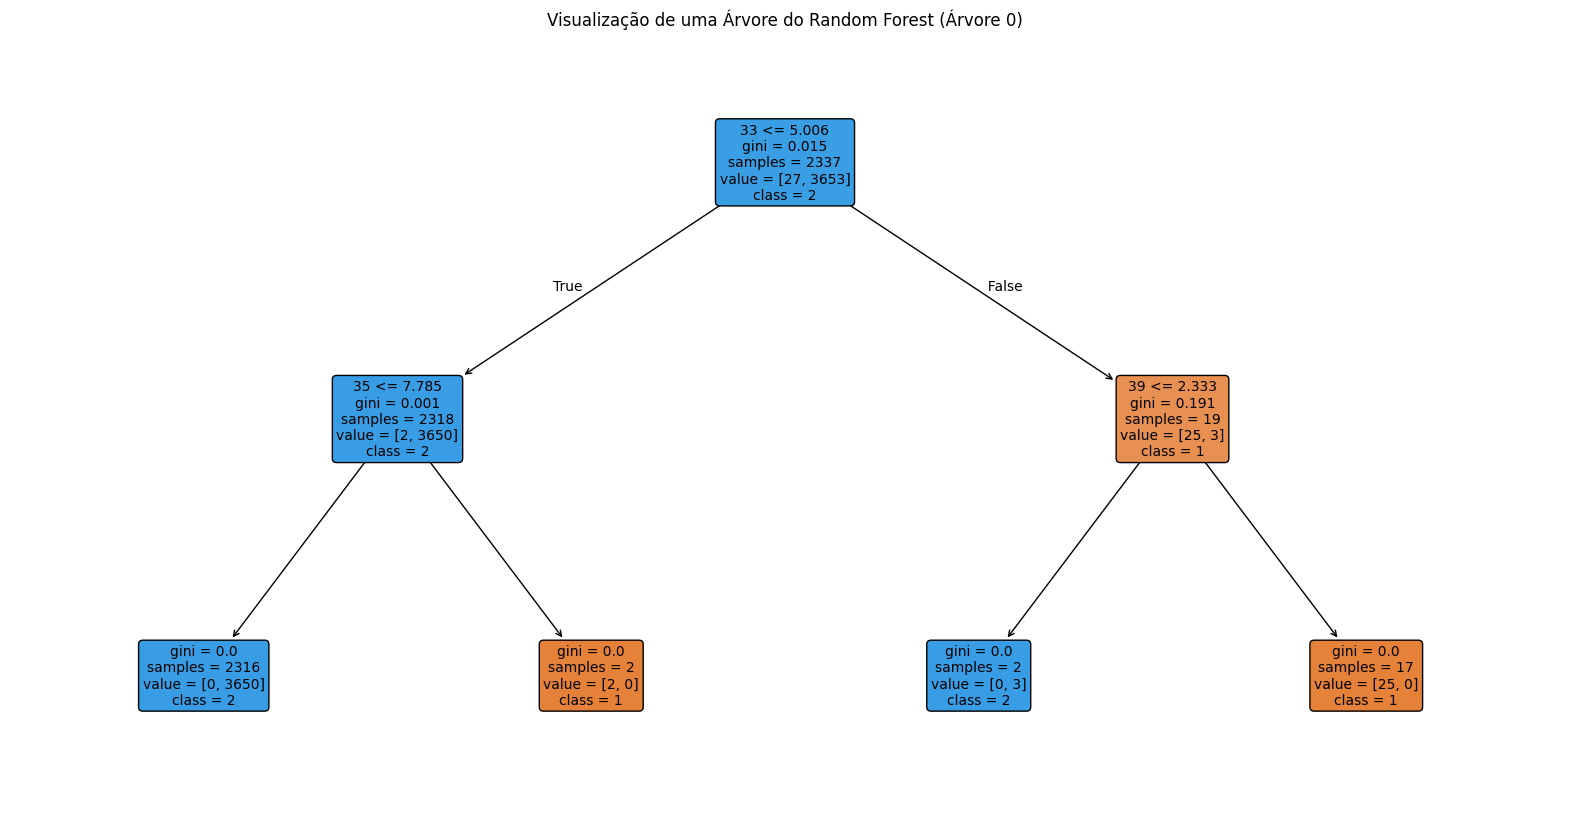


--- Regras da Árvore 0 do Random Forest ---
|--- 33 <= 5.01
|   |--- 35 <= 7.79
|   |   |--- class: 1.0
|   |--- 35 >  7.79
|   |   |--- class: 0.0
|--- 33 >  5.01
|   |--- 39 <= 2.33
|   |   |--- class: 1.0
|   |--- 39 >  2.33
|   |   |--- class: 0.0



In [ ]:
from sklearn.tree import plot_tree, export_text
import matplotlib.pyplot as plt

# 1. Extrai o modelo Random Forest de dentro do melhor pipeline
modelo_rf = best_rf_model.named_steps['rf']

# 2. Seleciona uma árvore específica de dentro da floresta (vamos pegar a primeira: índice 0)
arvore_exemplo = modelo_rf.estimators_[0]

# 3. Gera a visualização gráfica da árvore escolhida
plt.figure(figsize=(20, 10))
plot_tree(
    arvore_exemplo,
    feature_names=X.columns,
    class_names=[str(c) for c in best_rf_model.classes_],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3 # Limitamos a profundidade a 3 no gráfico para não virar um borrão visual
)
plt.title("Visualização de uma Árvore do Random Forest (Árvore 0)")
plt.show()

# 4. Imprime as regras da árvore em formato de texto
print("\n--- Regras da Árvore 0 do Random Forest ---")
regras_arvore_rf = export_text(arvore_exemplo, feature_names=list(X.columns))
print(regras_arvore_rf)

## Random Forest : Curvas de Aprendizado


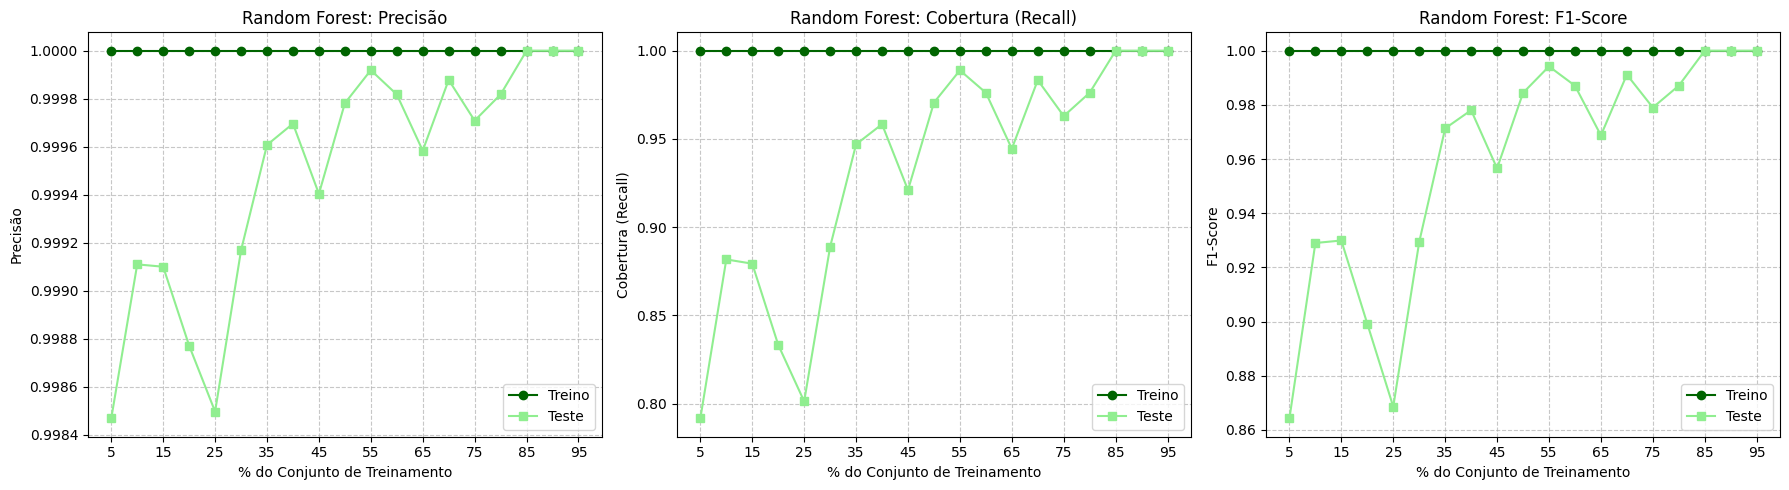

In [ ]:
# Proporções de treino de 5% a 95% (0.05 a 0.95)
train_proportions = np.round(np.arange(0.05, 0.96, 0.05), 2)

metrics_train_rf = {'precision': [], 'recall': [], 'f1': []}
metrics_test_rf = {'precision': [], 'recall': [], 'f1': []}

# A variável y_full já foi instanciada anteriormente (y_full = y)

for train_size in train_proportions:
    # Amostragem estratificada para garantir a mesma proporção de classes
    sss = StratifiedShuffleSplit(n_splits=3, train_size=train_size, test_size=1.0-train_size, random_state=42)

    tr_prec, tr_rec, tr_f1 = [], [], []
    te_prec, te_rec, te_f1 = [], [], []

    for train_idx, test_idx in sss.split(X, y_full):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y_full.iloc[train_idx], y_full.iloc[test_idx]

        # Treina o modelo com a proporção atual
        best_rf_model.fit(X_tr, y_tr)

        # Previsões
        y_tr_pred = best_rf_model.predict(X_tr)
        y_te_pred = best_rf_model.predict(X_te)

        # Cálculos das métricas ('macro')
        tr_prec.append(precision_score(y_tr, y_tr_pred, average='macro', zero_division=0))
        tr_rec.append(recall_score(y_tr, y_tr_pred, average='macro', zero_division=0))
        tr_f1.append(f1_score(y_tr, y_tr_pred, average='macro', zero_division=0))

        te_prec.append(precision_score(y_te, y_te_pred, average='macro', zero_division=0))
        te_rec.append(recall_score(y_te, y_te_pred, average='macro', zero_division=0))
        te_f1.append(f1_score(y_te, y_te_pred, average='macro', zero_division=0))

    metrics_train_rf['precision'].append(np.mean(tr_prec))
    metrics_train_rf['recall'].append(np.mean(tr_rec))
    metrics_train_rf['f1'].append(np.mean(tr_f1))

    metrics_test_rf['precision'].append(np.mean(te_prec))
    metrics_test_rf['recall'].append(np.mean(te_rec))
    metrics_test_rf['f1'].append(np.mean(te_f1))

# Plotagem
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metric_names = [('precision', 'Precisão'), ('recall', 'Cobertura (Recall)'), ('f1', 'F1-Score')]

for ax, (key, title) in zip(axes, metric_names):
    ax.plot(train_proportions * 100, metrics_train_rf[key], label='Treino', marker='o', color='darkgreen')
    ax.plot(train_proportions * 100, metrics_test_rf[key], label='Teste', marker='s', color='lightgreen')
    ax.set_title(f'Random Forest: {title}')
    ax.set_xlabel('% do Conjunto de Treinamento')
    ax.set_ylabel(title)
    ax.set_xticks(np.arange(5, 100, 10))
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend()

plt.tight_layout()
plt.show()